In [1]:
import sqlite3
import json
import pandas as pd

DB_PATH = "../analytics_sample.db"

conn = sqlite3.connect(DB_PATH)
audit_df = pd.read_sql_query("SELECT * FROM audit_log", conn)
conn.close()

assignments = audit_df[audit_df["tool_name"] == "assign_task"].copy()
outcomes = audit_df[audit_df["tool_name"] == "task_outcome"].copy()

def parse_assignment(row):
    args = json.loads(row["arguments"])
    result = json.loads(row["result"])
    return pd.Series({
        "task_id": result["task_id"],
        "robot_id": args["robot_id"],
        "from_zone": args["from_zone"],
        "to_zone": args["to_zone"],
        "assigned_tick": result["tick"],
        "battery_at_assignment": result["battery_at_assignment"],
        "distance": result["distance"],
    })

def parse_outcome(row):
    result = json.loads(row["result"])
    return pd.Series({
        "task_id": json.loads(row["arguments"])["task_id"],
        "status": row["reason"],  # "COMPLETED" ya "FAILED"
        "duration_ticks": result["duration_ticks"],
    })

assignments_clean = assignments.apply(parse_assignment, axis=1)
outcomes_clean = outcomes.apply(parse_outcome, axis=1)

print(f"Assignments: {len(assignments_clean)}, Outcomes: {len(outcomes_clean)}")
assignments_clean.head()

Assignments: 226, Outcomes: 223


,task_id,robot_id,from_zone,to_zone,assigned_tick,battery_at_assignment,distance
0,T-0001,R3,Dispatch,Charging,2,100.0,21
1,T-0002,R2,Storage,Packaging,18,100.0,9
3,T-0003,R3,Charging,Pickup,32,88.5,18
6,T-0004,R3,Pickup,Storage,40,88.5,5
7,T-0005,R2,Packaging,Storage,62,93.0,9


In [2]:
dataset = assignments_clean.merge(outcomes_clean, on="task_id", how="inner")

print(f"Final dataset size: {len(dataset)}")
print(f"\nClass balance:\n{dataset['status'].value_counts()}")
print(f"\nClass balance (%):\n{dataset['status'].value_counts(normalize=True) * 100}")

dataset.head(10)

Final dataset size: 223

Class balance:
status
COMPLETED    135
FAILED        88
Name: count, dtype: int64

Class balance (%):
status
COMPLETED    60.538117
FAILED       39.461883
Name: proportion, dtype: float64


,task_id,robot_id,from_zone,to_zone,assigned_tick,battery_at_assignment,distance,status,duration_ticks
0,T-0001,R3,Dispatch,Charging,2,100.0,21,COMPLETED,23
1,T-0002,R2,Storage,Packaging,18,100.0,9,COMPLETED,14
2,T-0003,R3,Charging,Pickup,32,88.5,18,FAILED,0
3,T-0004,R3,Pickup,Storage,40,88.5,5,COMPLETED,23
4,T-0005,R2,Packaging,Storage,62,93.0,9,FAILED,8
5,T-0006,R1,Charging,Dispatch,68,100.0,21,COMPLETED,34
6,T-0007,R3,Dispatch,Pickup,79,77.0,13,COMPLETED,29
7,T-0008,R2,Storage,Packaging,111,89.5,9,FAILED,8
8,T-0009,R3,Packaging,Storage,119,62.5,9,COMPLETED,13
9,T-0010,R3,Dispatch,Storage,134,56.0,16,FAILED,11


In [3]:
import pandas as pd

features = pd.get_dummies(
    dataset[["robot_id", "from_zone", "to_zone", "battery_at_assignment", "distance"]],
    columns=["robot_id", "from_zone", "to_zone"],
)

target = (dataset["status"] == "FAILED").astype(int)

print(f"Feature columns: {list(features.columns)}")
print(f"Features shape: {features.shape}")
features.head()

Feature columns: ['battery_at_assignment', 'distance', 'robot_id_R1', 'robot_id_R2', 'robot_id_R3', 'from_zone_Charging', 'from_zone_Dispatch', 'from_zone_Packaging', 'from_zone_Pickup', 'from_zone_Storage', 'to_zone_Charging', 'to_zone_Dispatch', 'to_zone_Packaging', 'to_zone_Pickup', 'to_zone_Storage']
Features shape: (223, 15)


,battery_at_assignment,distance,robot_id_R1,robot_id_R2,robot_id_R3,from_zone_Charging,from_zone_Dispatch,from_zone_Packaging,from_zone_Pickup,from_zone_Storage,to_zone_Charging,to_zone_Dispatch,to_zone_Packaging,to_zone_Pickup,to_zone_Storage
0,100.0,21,False,False,True,False,True,False,False,False,True,False,False,False,False
1,100.0,9,False,True,False,False,False,False,False,True,False,False,True,False,False
2,88.5,18,False,False,True,True,False,False,False,False,False,False,False,True,False
3,88.5,5,False,False,True,False,False,False,True,False,False,False,False,False,True
4,93.0,9,False,True,False,False,False,True,False,False,False,False,False,False,True


In [4]:
from sklearn.model_selection import train_test_split

dataset_sorted = dataset.sort_values("assigned_tick").reset_index(drop=True)
features_sorted = features.loc[dataset_sorted.index]
target_sorted = target.loc[dataset_sorted.index]

split_point = int(len(dataset_sorted) * 0.8)

X_train = features_sorted.iloc[:split_point]
X_test = features_sorted.iloc[split_point:]
y_train = target_sorted.iloc[:split_point]
y_test = target_sorted.iloc[split_point:]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")
print(f"Train failure rate: {y_train.mean()*100:.1f}%")
print(f"Test failure rate: {y_test.mean()*100:.1f}%")

Train size: 178, Test size: 45
Train failure rate: 41.6%
Test failure rate: 31.1%


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_preds = baseline.predict(X_test)

print("=== Baseline (always predict majority class) ===")
print(classification_report(y_test, baseline_preds, target_names=["COMPLETED", "FAILED"], zero_division=0))

=== Baseline (always predict majority class) ===
              precision    recall  f1-score   support

   COMPLETED       0.69      1.00      0.82        31
      FAILED       0.00      0.00      0.00        14

    accuracy                           0.69        45
   macro avg       0.34      0.50      0.41        45
weighted avg       0.47      0.69      0.56        45



In [6]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
log_reg_preds = log_reg.predict(X_test)

print("=== Logistic Regression ===")
print(classification_report(y_test, log_reg_preds, target_names=["COMPLETED", "FAILED"], zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

   COMPLETED       0.77      0.74      0.75        31
      FAILED       0.47      0.50      0.48        14

    accuracy                           0.67        45
   macro avg       0.62      0.62      0.62        45
weighted avg       0.67      0.67      0.67        45



In [7]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=5)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

print("=== Random Forest ===")
print(classification_report(y_test, rf_preds, target_names=["COMPLETED", "FAILED"], zero_division=0))

=== Random Forest ===
              precision    recall  f1-score   support

   COMPLETED       0.73      0.71      0.72        31
      FAILED       0.40      0.43      0.41        14

    accuracy                           0.62        45
   macro avg       0.57      0.57      0.57        45
weighted avg       0.63      0.62      0.63        45



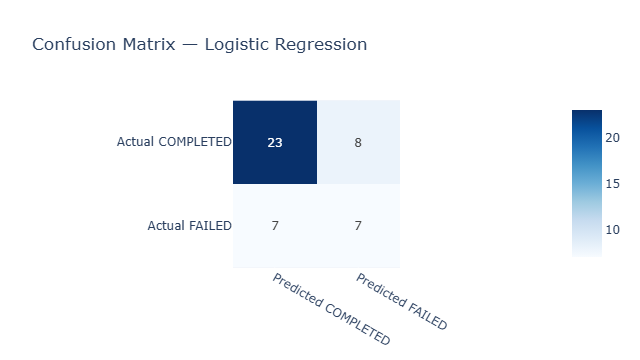

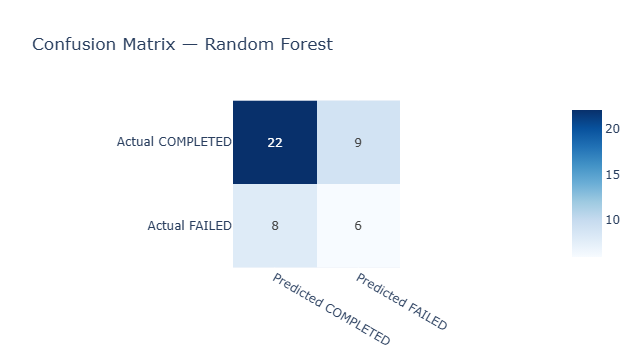

In [8]:
from sklearn.metrics import confusion_matrix
import plotly.express as px
import numpy as np

fig_data = []
for name, preds in [("Logistic Regression", log_reg_preds), ("Random Forest", rf_preds)]:
    cm = confusion_matrix(y_test, preds)
    fig = px.imshow(
        cm, text_auto=True,
        x=["Predicted COMPLETED", "Predicted FAILED"],
        y=["Actual COMPLETED", "Actual FAILED"],
        title=f"Confusion Matrix — {name}",
        color_continuous_scale="Blues",
    )
    fig.show()

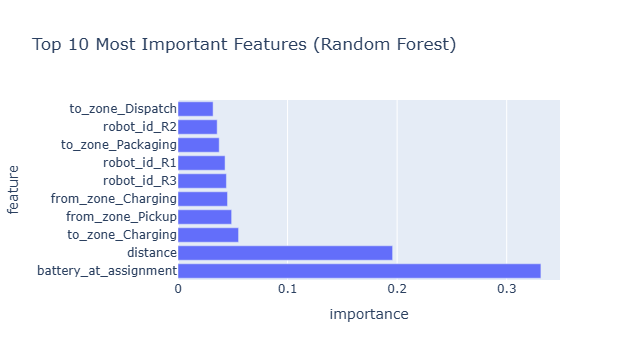

In [9]:
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False).head(10)

fig = px.bar(
    importance_df, x="importance", y="feature", orientation="h",
    title="Top 10 Most Important Features (Random Forest)",
)
fig.show()

## Conclusion

**Problem:** Predict if a warehouse task will fail before it's assigned.

**Best model:** Logistic Regression (macro F1 = 0.62) — outperformed Random Forest (0.57)
on this dataset size (178 training rows), likely because Random Forest needs more data
to avoid overfitting noise.

**Key finding:** `distance` and `battery_at_assignment` are by far the most predictive
features — this matches the underlying simulation logic (failure probability accumulates
per movement step, so longer tasks and lower starting battery both increase risk).
`robot_id` and specific zones showed negligible importance, confirming there's no
artificial bias built into the simulation between robots or zones.

**Honest limitation:** Overall predictive power is modest (macro F1 = 0.62, only
moderately above the 0.41 baseline). This is expected — task failure in this simulation
is driven by a per-step random probability (2%), which is inherently close to random
noise rather than a strong learnable pattern. The model correctly identifies that longer,
lower-battery tasks are riskier, but cannot predict individual failures with high
confidence — which is the correct and honest conclusion for this kind of stochastic event.

In [10]:
import joblib

final_model = LogisticRegression(max_iter=1000, random_state=42)
final_model.fit(features, target)

joblib.dump(final_model, "../ml_model.joblib")
joblib.dump(list(features.columns), "../ml_model_columns.joblib")

print("Model saved: ml_model.joblib")
print(f"Feature columns saved: {len(features.columns)} columns")

Model saved: ml_model.joblib
Feature columns saved: 15 columns


In [11]:
import joblib

baseline_rate = target.mean()
joblib.dump(baseline_rate, "../ml_baseline_rate.joblib")
print(f"Baseline failure rate saved: {baseline_rate*100:.1f}%")

Baseline failure rate saved: 39.5%
